## If Michael Jordan shoots 100 free throws, what's the probability he makes all 100?

X is the amount of shots Michael Jordan makes in a single trial of 100 free throws. Integers 0-100 are possible for this simulation.
One trial consists of 100 simulated free throw shots. Each trial has two outcomes, hit (83.5%) or miss (1-p = 16.5%). The outcome at the end will be be the count of total shots made, X.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binom

In [2]:
n = 100
p = 0.835
k = 100
num_sims = 100_000

In [3]:
pmf_exact = binom.pmf(k=k, n=n, p=p)
std_theoretical = binom.std(n=n, p=p)  # Formula: sqrt(n * p * (1 - p))

In [4]:
print("=== THEORETICAL RESULT ===")
print(f"P(X = {k}): {pmf_exact}")
print(f"Scientific Notation: {pmf_exact:.4e}")
print(f"As Percentage: {pmf_exact * 100:.8f}%")
print(f"Theoretical Standard Deviation: {std_theoretical:.4f}\n")

=== THEORETICAL RESULT ===
P(X = 100): 1.4745094096269886e-08
Scientific Notation: 1.4745e-08
As Percentage: 0.00000147%
Theoretical Standard Deviation: 3.7118



In [5]:
np.random.seed(42)
simulations = np.random.binomial(n=n, p=p, size=num_sims)

In [6]:
exact_matches = np.sum(simulations == k)
sim_prob = exact_matches / num_sims
avg_made = np.mean(simulations)
std_sim = np.std(simulations)

In [7]:
print("=== SIMULATION RESULTS ===")
print(f"Total Trials: {num_sims:,}")
print(f"Trials making {k}/{n}: {exact_matches}")
print(f"Simulated Probability: {sim_prob}")
print(f"Average Made Shots: {avg_made:.2f}")
print(f"Simulated Standard Deviation: {std_sim:.4f}\n")

=== SIMULATION RESULTS ===
Total Trials: 100,000
Trials making 100/100: 0
Simulated Probability: 0.0
Average Made Shots: 83.51
Simulated Standard Deviation: 3.7005



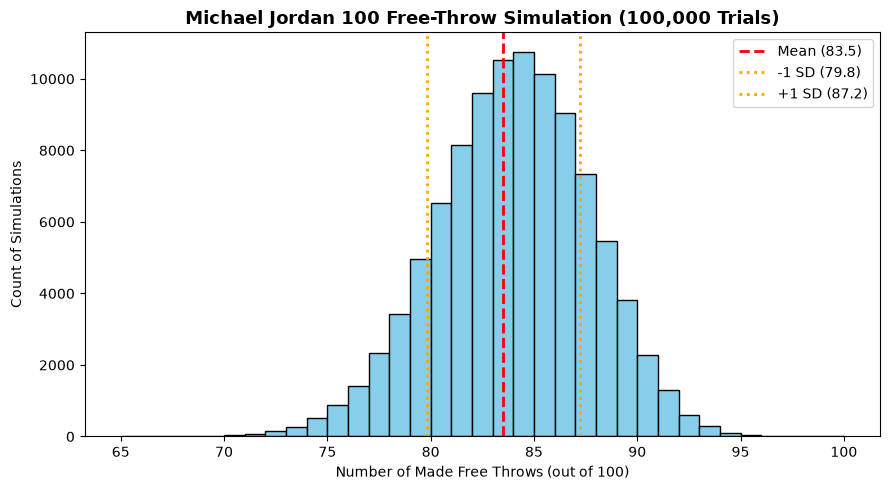

In [8]:
plt.figure(figsize=(9, 5))
plt.hist(simulations, bins=range(65, 101), color='skyblue', edgecolor='black')
plt.axvline(
    x=avg_made,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Mean ({avg_made:.1f})',
)

plt.axvline(
    x=avg_made - std_sim,
    color='orange',
    linestyle=':',
    linewidth=2,
    label=f'-1 SD ({avg_made - std_sim:.1f})',
)

plt.axvline(
    x=avg_made + std_sim,
    color='orange',
    linestyle=':',
    linewidth=2,
    label=f'+1 SD ({avg_made + std_sim:.1f})',
)

plt.title(
    'Michael Jordan 100 Free-Throw Simulation (100,000 Trials)',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel('Number of Made Free Throws (out of 100)')
plt.ylabel('Count of Simulations')
plt.legend()
plt.tight_layout()
plt.show()

The histogram displays our mean of 83.5 and our standard deviation of 3.71 in proportion to the data collected.

## Our results indicate that you are more likely to be struck by lightning (1 in 1,222,000) than for Michael Jordan to make 100 free-throws (1 in 67.8 million). Our binomial mean of 83.5 means that, on average, Michael Jordan would make 83.5 shots per trial. Our standard deviation of 3.71 means that 68% of trials fell within 3.71 shots from the mean. Our PMF calculated $1.47 \times 10^{-8}$, but our simulation ran zero perfect trials.